# Этап 7. Проверка гипотез

Гипотезы сформулированы на этапе 1, до анализа. Здесь проверяем их статистически.

## Оглавление
1. [Настройка и правила проверки](#setup)
2. [H1: доход и медицина](#h1)
3. [H2: сырьевые регионы](#h2)
4. [H3: сокращение разрыва](#h3)
5. [H4: поправка на прожиточный минимум](#h4)
6. [H5: миграция и доход](#h5)
7. [Поправка на множественные сравнения](#holm)
8. [Итоговая таблица](#summary)

<a id="setup"></a>
## 1. Настройка и правила проверки

**Правила, зафиксированные до расчётов:**
- уровень значимости **α = 0,05**;
- **основной срез** — 20 регионов в 2024 г.; остальные разрезы — проверка устойчивости, решение по ним не меняется;
- сравнение групп — **U-тест Манна-Уитни**: в группах от 3 до 16 регионов, проверить нормальность на таких выборках почти невозможно, а ранговый тест её не требует. Дополнительно — t-тест Уэлча, если обе группы проходят тест Шапиро-Уилка;
- кроме p-value, всегда указываем **размер эффекта**: rank-biserial r (от −1 до 1; |r| ≥ 0,3 — средний эффект, ≥ 0,5 — большой);
- в конце — **поправка Холма** на то, что мы проверяем несколько гипотез сразу.

⚠️ **Главное ограничение — маленькие выборки.** В группе сырьевых регионов 4 региона из 20. Даже реальная разница может оказаться «незначимой» — у теста мало мощности. Поэтому «не значимо» читаем как «данных недостаточно, чтобы утверждать», а не как «разницы нет».

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9", "grid.color": "#e6e4dd",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)

BLUE, ORANGE = "#2a78d6", "#eb6834"
GRAY, LIGHT, INK, MUTED = "#b4b2a9", "#d9d7cf", "#0b0b0b", "#52514e"
ALPHA, SEED = 0.05, 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMAGES = ROOT / "images"

regions = pd.read_csv(DATA / "panel_regions_clean.csv")
units = pd.read_csv(DATA / "panel_units_clean.csv")
LAST = int(regions.year.max())
r = regions[regions.year == LAST].copy()

def mann_whitney(a, b, alternative="two-sided"):
    res = stats.mannwhitneyu(a, b, alternative=alternative)
    rank_biserial = 2 * res.statistic / (len(a) * len(b)) - 1
    return {"U": res.statistic, "p-value": res.pvalue, "эффект r": rank_biserial,
            "n1": len(a), "n2": len(b), "медиана 1": np.median(a), "медиана 2": np.median(b)}

def label_right(ax, x, values: pd.Series, gap_share=0.045):
    # подписи точек справа от столбца, раздвинутые по вертикали, чтобы не налезали
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * gap_share
    prev = -np.inf
    for name, v in values.sort_values().items():
        y = max(v, prev + gap)
        ax.text(x + 0.34, y, name, va="center", fontsize=8, color=MUTED)
        prev = y

RESULTS = []   # сюда собираем все тесты для итоговой таблицы
print(f"Основной срез: {len(r)} регионов, {LAST} г.")

Основной срез: 20 регионов, 2024 г.


<a id="h1"></a>
## 2. H1: доход сильнее связан с экономикой и занятостью, чем с медициной

Проверена на этапе 6 регрессией с кластерным бутстрепом. Переносим результат.

In [2]:
h1 = pd.DataFrame([
    {"фактор": "ВРП на душу", "коэф.": 0.891, "95% ДИ": "0,72 … 1,05", "значим": "да"},
    {"фактор": "Врачи на 10 тыс.", "коэф.": 0.019, "95% ДИ": "−0,20 … 0,18", "значим": "нет"},
    {"фактор": "Неформальная занятость", "коэф.": -0.002, "95% ДИ": "−0,26 … 0,14", "значим": "нет"},
])
RESULTS.append({"гипотеза": "H1", "формулировка": "доход сильнее связан с экономикой и занятостью, чем с медициной",
                "тест": "регрессия + кластерный бутстреп (этап 6)", "p-value": np.nan, "эффект": "β врачей = 0,02, ДИ включает 0"})
h1

,фактор,коэф.,95% ДИ,значим
0,ВРП на душу,0.891,"0,72 … 1,05",да
1,Врачи на 10 тыс.,0.019,"−0,20 … 0,18",нет
2,Неформальная занятость,-0.002,"−0,26 … 0,14",нет


**Решение: частично подтверждается.** Доход определяется экономикой региона; связь с обеспеченностью врачами при учёте ВРП незначима. Но неформальная занятость (часть «занятости» в формулировке) тоже незначима, а роль образования проверить нельзя — по регионам нет данных.

<a id="h2"></a>
## 3. H2: сырьевые регионы богаче, но живут там не дольше

Сырьевые (заданы на этапе 1): Атырауская, Мангистауская, Западно-Казахстанская, Актюбинская.
- **H2a** (односторонний тест): доход в сырьевых регионах **выше**;
- **H2b** (двусторонний): продолжительность жизни **различается**. Гипотеза ожидает, что различия не будет.

In [3]:
oil = r[r.is_resource]
other = r[~r.is_resource]

h2a = mann_whitney(oil.income_pc, other.income_pc, "greater")
h2b = mann_whitney(oil.life_expectancy, other.life_expectancy, "two-sided")

# Разница продолжительности жизни: оценка Ходжеса-Лемана и бутстреп-интервал
diff = np.median(np.subtract.outer(oil.life_expectancy.values, other.life_expectancy.values))
rng = np.random.default_rng(SEED)
boot = [np.median(rng.choice(oil.life_expectancy, len(oil))) - np.median(rng.choice(other.life_expectancy, len(other)))
        for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])

table = pd.DataFrame([h2a, h2b], index=["H2a: доход выше", "H2b: продолжительность жизни различается"])
print(f"Разница продолжительности жизни (сырьевые − остальные): {diff:+.2f} года, 95% ДИ {lo:+.1f} … {hi:+.1f}")
table.round(3)

Разница продолжительности жизни (сырьевые − остальные): +0.29 года, 95% ДИ -0.7 … +1.3


,U,p-value,эффект r,n1,n2,медиана 1,медиана 2
H2a: доход выше,45.0,0.124,0.406,4,16,229593.500,191382.50
H2b: продолжительность жизни различается,40.0,0.494,0.250,4,16,75.235,74.88


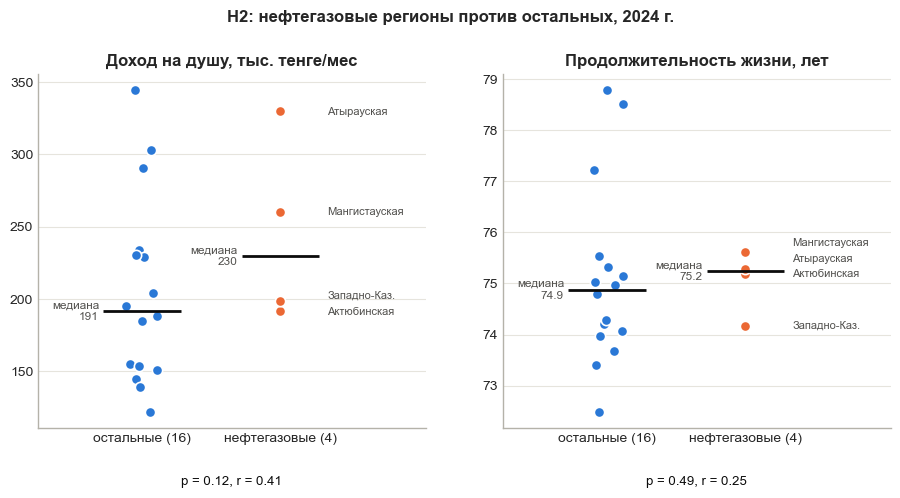

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
rng_jit = np.random.default_rng(1)
for ax, col, title, scale, fmt in [(axes[0], "income_pc", "Доход на душу, тыс. тенге/мес", 1000, "{:.0f}"),
                                   (axes[1], "life_expectancy", "Продолжительность жизни, лет", 1, "{:.1f}")]:
    for x, (grp, color, label) in enumerate([(other, BLUE, "остальные"), (oil, ORANGE, "нефтегазовые")]):
        vals = grp[col] / scale
        jitter = 0 if label == "нефтегазовые" else rng_jit.uniform(-0.12, 0.12, len(vals))
        ax.scatter(np.full(len(vals), x) + jitter, vals, color=color, s=55, edgecolor="white", linewidth=1.2, zorder=3)
        ax.hlines(vals.median(), x - 0.28, x + 0.28, color=INK, lw=2, zorder=4)
        ax.text(x - 0.31, vals.median(), "медиана\n" + fmt.format(vals.median()), va="center", ha="right",
                fontsize=8.5, color=MUTED)
    ax.set_xticks([0, 1], ["остальные (16)", "нефтегазовые (4)"])
    ax.set_xlim(-0.75, 2.05)
    label_right(ax, 1, (oil.set_index("region")[col] / scale).rename(lambda n: n.replace("-Казахстанская", "-Каз.")))
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].text(0.5, -0.16, f"p = {h2a['p-value']:.2f}, r = {h2a['эффект r']:.2f}", transform=axes[0].transAxes,
             ha="center", fontsize=9.5, color=INK)
axes[1].text(0.5, -0.16, f"p = {h2b['p-value']:.2f}, r = {h2b['эффект r']:.2f}", transform=axes[1].transAxes,
             ha="center", fontsize=9.5, color=INK)
fig.suptitle(f"H2: нефтегазовые регионы против остальных, {LAST} г.", fontweight="bold", y=1.02)
fig.savefig(IMAGES / "16_h2_resource.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат на основном срезе:**
- **H2a не подтверждается статистически** (p = 0,12). Медиана дохода у нефтегазовых регионов выше (230 против 191 тыс.), эффект средний (r = 0,41), но группа неоднородна: Атырау и Мангистау — в топ-5 по доходу, а ЗКО и Актюбинская — ниже среднего по стране. При 4 регионах в группе такой разброс не даёт значимости.
- **H2b: различий в продолжительности жизни не найдено** (p = 0,49). Оценка разницы — +0,3 года, 95% интервал от −0,7 до +1,3 года. То есть если разница и есть, она не больше года.

Проверяем устойчивость: другие годы и расширенное определение «сырьевого» региона.

In [5]:
avg = (regions[regions.year >= LAST - 2]
       .groupby(["region", "is_resource"], as_index=False)[["income_pc", "life_expectancy"]].mean())
unit_avg = units.groupby(["unit_name", "is_resource"], as_index=False)[["income_pc", "life_expectancy"]].mean()
# Расширенная группа «добывающие»: нефть и газ + металлы и уголь (медь — Ұлытау, уголь и металлургия — Карагандинская, Павлодарская)
EXTRACTIVE = {"Атырауская", "Мангистауская", "Западно-Казахстанская", "Актюбинская", "Ұлытау", "Карагандинская", "Павлодарская"}
r["extractive"] = r.region.isin(EXTRACTIVE)

variants = {
    f"основной: 20 регионов, {LAST}": (r, "is_resource"),
    f"20 регионов, среднее {LAST - 2}–{LAST}": (avg, "is_resource"),
    "16 единиц, среднее 2015–2024": (unit_avg, "is_resource"),
    f"добывающие (7) против остальных (13), {LAST} *": (r, "extractive"),
}
rows = []
for name, (d, flag) in variants.items():
    g1, g2 = d[d[flag]], d[~d[flag]]
    a = mann_whitney(g1.income_pc, g2.income_pc, "greater")
    b = mann_whitney(g1.life_expectancy, g2.life_expectancy, "two-sided")
    rows.append({"разрез": name, "n": f"{a['n1']} vs {a['n2']}",
                 "H2a p (доход выше)": a["p-value"], "H2a r": a["эффект r"],
                 "H2b p (жизнь различается)": b["p-value"], "H2b r": b["эффект r"]})
pd.DataFrame(rows).set_index("разрез").round(3)

,n,H2a p (доход выше),H2a r,H2b p (жизнь различается),H2b r
разрез,,,,,
"основной: 20 регионов, 2024",4 vs 16,0.124,0.406,0.494,0.250
"20 регионов, среднее 2022–2024",4 vs 16,0.145,0.375,0.385,0.312
"16 единиц, среднее 2015–2024",4 vs 12,0.131,0.417,0.212,0.458
"добывающие (7) против остальных (13), 2024 *",7 vs 13,0.018,0.582,0.311,-0.297


\* Расширенная группа задана после того, как мы увидели данные (Ұлытау в EDA), поэтому это **разведочный** результат, а не проверка гипотезы.

**Решение по H2: частично подтверждается.**
- Вторая часть устойчива во всех разрезах: **сырьевые регионы не живут дольше** остальных (p 0,21–0,49, разница меньше года).
- Первая часть — **«сырьевые богаче» — для нефтегазовой группы статистически не подтверждается** ни в одном разрезе (p 0,12–0,15), хотя направление и эффект средний (r ≈ 0,4). Если считать сырьевыми все добывающие регионы, разница становится значимой (p = 0,02, r = 0,58), но это разведочный вывод.
- Это согласуется с этапом 6: ЗКО и Актюбинская получают на 8–12% меньше дохода, чем предсказывает их экономика, — нефть есть, а доходов населения «по нефти» нет.

In [6]:
RESULTS.append({"гипотеза": "H2a", "формулировка": "в нефтегазовых регионах доход выше",
                "тест": "Манн-Уитни, односторонний", "p-value": h2a["p-value"],
                "эффект": f"r = {h2a['эффект r']:.2f}; медианы {h2a['медиана 1'] / 1000:.0f} vs {h2a['медиана 2'] / 1000:.0f} тыс."})
RESULTS.append({"гипотеза": "H2b", "формулировка": "продолжительность жизни не выше (ожидаем отсутствие различий)",
                "тест": "Манн-Уитни, двусторонний", "p-value": h2b["p-value"],
                "эффект": f"разница {diff:+.1f} года, 95% ДИ {lo:+.1f} … {hi:+.1f}"})

<a id="h3"></a>
## 4. H3: разрыв между регионами сокращается

Две проверки на 16 сопоставимых единицах:
- **σ-конвергенция** — есть ли убывающий тренд у коэффициента вариации. Тест **тау Кендалла** (непараметрический тест на монотонный тренд — не требует нормальности и устойчив к выбросам);
- **β-конвергенция** — росли ли быстрее регионы, которые были беднее в 2015 г. (регрессия, этап 5).

In [7]:
def cv(x):
    return x.std(ddof=0) / x.mean() * 100

def wcv(g):
    m = np.average(g.income_pc, weights=g.population)
    return np.sqrt(np.average((g.income_pc - m) ** 2, weights=g.population)) / m * 100

cv_year = units.groupby("year").income_pc.agg(cv)
wcv_year = pd.Series({y: wcv(g) for y, g in units.groupby("year")})

inc = units.pivot(index="unit_name", columns="year", values="income_pc")
cagr = ((inc[LAST] / inc[2015]) ** (1 / (LAST - 2015)) - 1) * 100
beta = stats.linregress(np.log(inc[2015]), cagr)

h3 = pd.DataFrame([
    {"проверка": "CV снижается (2015–2024)", "тау / r": stats.kendalltau(cv_year.index, cv_year)[0],
     "p-value": stats.kendalltau(cv_year.index, cv_year)[1]},
    {"проверка": "CV взвешенный снижается (2015–2024)", "тау / r": stats.kendalltau(wcv_year.index, wcv_year)[0],
     "p-value": stats.kendalltau(wcv_year.index, wcv_year)[1]},
    {"проверка": "CV взвешенный снижается (2020–2024)", "тау / r": stats.kendalltau(wcv_year.loc[2020:].index, wcv_year.loc[2020:])[0],
     "p-value": stats.kendalltau(wcv_year.loc[2020:].index, wcv_year.loc[2020:])[1]},
    {"проверка": "β: бедные росли быстрее", "тау / r": beta.rvalue, "p-value": beta.pvalue},
]).set_index("проверка")
h3.round(4)

,тау / r,p-value
проверка,,
CV снижается (2015–2024),-0.8667,0.0001
CV взвешенный снижается (2015–2024),-0.6889,0.0047
CV взвешенный снижается (2020–2024),0.4000,0.4833
β: бедные росли быстрее,-0.7288,0.0014


**Решение по H3: подтверждается.** Коэффициент вариации снижается почти монотонно (τ = −0,87, p = 0,0001), бедные регионы растут быстрее (r = −0,73, p = 0,001). С учётом численности населения неравенство за 10 лет тоже снизилось (p = 0,005), но с 2020 г. тренда нет (p = 0,48): разрыв между мегаполисами и остальной страной перестал сокращаться.

In [8]:
tau_cv, p_cv = stats.kendalltau(cv_year.index, cv_year)
RESULTS.append({"гипотеза": "H3", "формулировка": "разрыв в доходах между регионами сокращается",
                "тест": "тау Кендалла (тренд CV) + β-регрессия", "p-value": p_cv,
                "эффект": f"τ = {tau_cv:.2f}; CV 39,7% → 28,7%; β: r = {beta.rvalue:.2f}"})

<a id="h4"></a>
## 5. H4: с поправкой на прожиточный минимум города теряют преимущество

Если гипотеза верна, должно выполняться два условия: (1) прожиточный минимум выше там, где выше доходы, и (2) поправка заметно меняет рейтинг, прежде всего для городов.

In [9]:
rho_pm, p_pm = stats.spearmanr(r.subsistence, r.income_pc)
rank_nom = r.income_pc.rank(ascending=False)
rank_real = r.income_to_subsistence.rank(ascending=False)
rho_rank, _ = stats.spearmanr(rank_nom, rank_real)
cities = r.region.str.startswith("г.")

print(f"(1) ПМ выше там, где выше доход: ρ = {rho_pm:.2f}, p = {p_pm:.3f}")
print(f"    но ПМ различается в {r.subsistence.max() / r.subsistence.min():.2f} раза, доход — в {r.income_pc.max() / r.income_pc.min():.1f} раза")
print(f"(2) совпадение рейтингов: ρ = {rho_rank:.2f}")
print(f"    города: сдвиг мест {(rank_nom - rank_real)[cities].astype(int).tolist()} "
      f"({', '.join(r.loc[cities, 'region'])})")

(1) ПМ выше там, где выше доход: ρ = 0.47, p = 0.036
    но ПМ различается в 1.37 раза, доход — в 2.8 раза
(2) совпадение рейтингов: ρ = 0.97
    города: сдвиг мест [-1, -1, 0] (г. Астана, г. Алматы, г. Шымкент)


**Решение по H4: не подтверждается.** Первое условие выполняется: в более богатых регионах прожиточный минимум действительно выше (ρ = 0,47, p = 0,04). Но различия в ПМ слишком малы (в 1,4 раза против 2,8 раза по доходу), чтобы изменить картину: рейтинги совпадают на 97%, а города теряют максимум одно место. Оговорка: ПМ не включает аренду жилья — именно её разница между мегаполисами и областями самая большая. Поэтому вернее сказать: **на доступных данных H4 не подтверждается**.

In [10]:
RESULTS.append({"гипотеза": "H4", "формулировка": "с поправкой на ПМ города теряют преимущество",
                "тест": "Спирмен: ПМ и доход; совпадение рейтингов", "p-value": p_pm,
                "эффект": f"ρ рейтингов = {rho_rank:.2f}; города теряют ≤ 1 места"})

<a id="h5"></a>
## 6. H5: регионы с оттоком населения отстают по доходам

Группы по знаку сальдо миграции: отток (< 0) и приток (≥ 0). Тест односторонний: доход в регионах с оттоком **ниже**.

In [11]:
out_, in_ = r[r.migration_per1000 < 0], r[r.migration_per1000 >= 0]
h5 = mann_whitney(out_.income_pc, in_.income_pc, "less")
sh_out, sh_in = stats.shapiro(out_.income_pc).pvalue, stats.shapiro(in_.income_pc).pvalue
welch = stats.ttest_ind(out_.income_pc, in_.income_pc, equal_var=False, alternative="less")

print(f"Приток в {LAST} г.: {', '.join(in_.region)}")
print(f"Шапиро-Уилк: отток p = {sh_out:.2f}, приток p = {sh_in:.2f} → нормальность не отвергается, t-тест Уэлча допустим")
print(f"t-тест Уэлча: t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}")
pd.DataFrame([h5], index=["H5: доход при оттоке ниже"]).round(3)

Приток в 2024 г.: Алматинская, Мангистауская, г. Астана, г. Алматы, г. Шымкент
Шапиро-Уилк: отток p = 0.32, приток p = 0.45 → нормальность не отвергается, t-тест Уэлча допустим
t-тест Уэлча: t = -0.87, p = 0.212


,U,p-value,эффект r,n1,n2,медиана 1,медиана 2
H5: доход при оттоке ниже,28.0,0.222,-0.253,15,5,194843.0,260252.0


In [12]:
unit_mig = units.groupby("unit_name")[["income_pc", "migration_per1000"]].mean()
unit_mig_clean = units[~units.migration_anomaly].groupby("unit_name")[["income_pc", "migration_per1000"]].mean()
reg_avg = regions[regions.year >= LAST - 2].groupby("region")[["income_pc", "migration_per1000"]].mean()

rows = []
for name, d in {f"основной: 20 регионов, {LAST}": r.set_index("region"),
                f"20 регионов, среднее {LAST - 2}–{LAST}": reg_avg,
                "16 единиц, среднее 2015–2024": unit_mig,
                "16 единиц, без аномалии 2016 г.": unit_mig_clean}.items():
    t = mann_whitney(d[d.migration_per1000 < 0].income_pc, d[d.migration_per1000 >= 0].income_pc, "less")
    rho, p_rho = stats.spearmanr(d.migration_per1000, d.income_pc)
    rows.append({"разрез": name, "отток / приток": f"{t['n1']} / {t['n2']}", "p (Манн-Уитни)": t["p-value"],
                 "эффект r": t["эффект r"], "ρ миграция–доход": rho, "p (Спирмен)": p_rho})
h5_rob = pd.DataFrame(rows).set_index("разрез")
print("Приток за 2015–2024 гг. (16 единиц): " + ", ".join(unit_mig[unit_mig.migration_per1000 >= 0].index))
h5_rob.round(3)

Приток за 2015–2024 гг. (16 единиц): Мангистауская, г. Алматы, г. Астана


,отток / приток,p (Манн-Уитни),эффект r,ρ миграция–доход,p (Спирмен)
разрез,,,,,
"основной: 20 регионов, 2024",15 / 5,0.222,-0.253,0.438,0.054
"20 регионов, среднее 2022–2024",15 / 5,0.249,-0.227,0.426,0.061
"16 единиц, среднее 2015–2024",13 / 3,0.012,-0.846,0.553,0.026
"16 единиц, без аномалии 2016 г.",13 / 3,0.012,-0.846,0.606,0.013


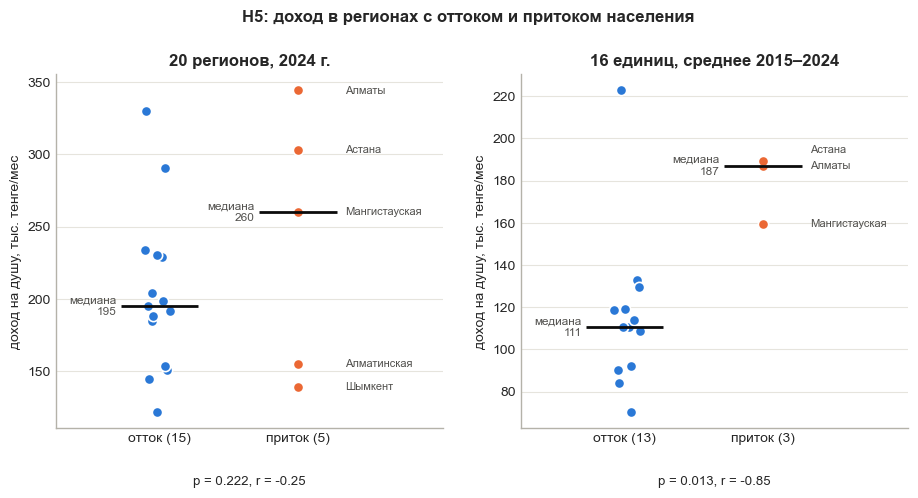

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=False)
rng_jit = np.random.default_rng(2)
for ax, (title, d, label_col) in zip(axes, [(f"20 регионов, {LAST} г.", r.set_index("region"), None),
                                           ("16 единиц, среднее 2015–2024", unit_mig, None)]):
    groups = [(d[d.migration_per1000 < 0], BLUE, "отток"), (d[d.migration_per1000 >= 0], ORANGE, "приток")]
    for x, (g, color, lab) in enumerate(groups):
        vals = g.income_pc / 1000
        jitter = 0 if lab == "приток" else rng_jit.uniform(-0.12, 0.12, len(vals))
        ax.scatter(np.full(len(vals), x) + jitter, vals, color=color, s=55, edgecolor="white", linewidth=1.2, zorder=3)
        ax.hlines(vals.median(), x - 0.28, x + 0.28, color=INK, lw=2, zorder=4)
        ax.text(x - 0.31, vals.median(), f"медиана\n{vals.median():.0f}", va="center", ha="right", fontsize=8.5, color=MUTED)
    t = mann_whitney(groups[0][0].income_pc, groups[1][0].income_pc, "less")
    ax.set_xticks([0, 1], [f"отток ({t['n1']})", f"приток ({t['n2']})"])
    ax.set_xlim(-0.75, 2.05)
    label_right(ax, 1, (groups[1][0].income_pc / 1000).rename(lambda n: n.replace("г. ", "")))
    ax.set_title(title)
    ax.set_ylabel("доход на душу, тыс. тенге/мес")
    ax.grid(axis="x", visible=False)
    ax.text(0.5, -0.16, f"p = {t['p-value']:.3f}, r = {t['эффект r']:.2f}", transform=ax.transAxes, ha="center", fontsize=9.5)
fig.suptitle("H5: доход в регионах с оттоком и притоком населения", fontweight="bold", y=1.02)
fig.savefig(IMAGES / "17_h5_migration.png", dpi=150, bbox_inches="tight")
plt.show()

**Решение по H5: не подтверждается на основном срезе, вывод неустойчив.**
- В 2024 г. медианный доход в регионах с оттоком ниже (195 против 260 тыс.), но разница незначима (p = 0,22). Мешает Шымкент: население туда едет, хотя доходы — одни из самых низких. Вероятно, это переезд из сёл соседней Туркестанской области в ближайший большой город, а не в богатый регион. Приток в Алматинскую область, вероятно, тоже идёт в пригороды Алматы, а не за доходами самой области.
- На горизонте 10 лет картина чёткая: устойчивый приток был только у трёх единиц — Астаны, Алматы и Мангистауской области, и все три — среди самых богатых (p = 0,01, эффект большой: r = −0,85). Аномалия 2016 г. на вывод не влияет.
- Связь сальдо миграции с доходом положительная, но на грани значимости (ρ ≈ 0,43, p ≈ 0,05–0,06).

Итог: **в долгосрочном плане люди уезжают из бедных регионов в богатые, но на одном году это не видно** — миграция в пригороды и ближайшие города смазывает картину. Поскольку основной срез был выбран заранее, решение — «не подтверждается»; долгосрочный результат — важное дополнение, а не замена.

In [14]:
RESULTS.append({"гипотеза": "H5", "формулировка": "в регионах с оттоком населения доход ниже",
                "тест": "Манн-Уитни, односторонний", "p-value": h5["p-value"],
                "эффект": f"r = {h5['эффект r']:.2f}; на 10 лет: p = {h5_rob.iloc[2]['p (Манн-Уитни)']:.3f}"})

<a id="holm"></a>
## 7. Поправка на множественные сравнения

Чем больше гипотез проверяем, тем выше шанс получить «значимый» результат случайно. **Поправка Холма** ужесточает порог: самый маленький p-value сравнивается с α / k, следующий — с α / (k − 1) и так далее. H2b в поправку не включаем: там мы ожидаем *отсутствие* различий, и поправка только облегчила бы «подтверждение».

In [15]:
def holm(pvals: pd.Series, alpha=ALPHA) -> pd.Series:
    order = pvals.sort_values()
    k = len(order)
    adjusted = np.maximum.accumulate([min(1, p * (k - i)) for i, p in enumerate(order)])
    return pd.Series(adjusted, index=order.index).reindex(pvals.index)

summary = pd.DataFrame(RESULTS).set_index("гипотеза")
testable = summary["p-value"].notna() & (summary.index != "H2b")
summary.loc[testable, "p (Холм)"] = holm(summary.loc[testable, "p-value"])
summary[["тест", "p-value", "p (Холм)"]].round(4)

,тест,p-value,p (Холм)
гипотеза,,,
H1,регрессия + кластерный бутстреп (этап 6),NaN,NaN
H2a,"Манн-Уитни, односторонний",0.1243,0.2485
H2b,"Манн-Уитни, двусторонний",0.4941,NaN
H3,тау Кендалла (тренд CV) + β-регрессия,0.0001,0.0005
H4,Спирмен: ПМ и доход; совпадение рейтингов,0.0362,0.1086
H5,"Манн-Уитни, односторонний",0.2223,0.2485


**Вывод:** после поправки значимой остаётся только H3 (p = 0,0005). H4 формально была значима по первому условию (p = 0,04), но после поправки — нет (0,11); на решение это не влияет, H4 отвергнута по второму условию.

<a id="summary"></a>
## 8. Итоговая таблица

In [16]:
DECISIONS = {
    "H1": "⚠️ частично: медицина не влияет при учёте ВРП; образование не проверено (нет данных)",
    "H2a": "❌ не подтверждается (p = 0,12): ЗКО и Актюбинская ниже среднего по доходу",
    "H2b": "✅ подтверждается: различий нет, разница < 1 года",
    "H3": "✅ подтверждается: разрыв сократился, но с 2020 г. мегаполисы держат отрыв",
    "H4": "❌ не подтверждается: ПМ различается слишком мало, рейтинг почти не меняется",
    "H5": "❌ на основном срезе нет; ✅ на горизонте 10 лет — люди едут в 3 самых богатых региона",
}
final = summary.copy()
final["решение"] = final.index.map(DECISIONS)
final = final[["формулировка", "тест", "p-value", "p (Холм)", "эффект", "решение"]]
final.to_csv(DATA / "hypotheses_summary.csv", encoding="utf-8-sig")
final

,формулировка,тест,p-value,p (Холм),эффект,решение
гипотеза,,,,,,
H1,"доход сильнее связан с экономикой и занятостью, чем с медициной",регрессия + кластерный бутстреп (этап 6),NaN,NaN,"β врачей = 0,02, ДИ включает 0",⚠️ частично: медицина не влияет при учёте ВРП; образование не проверено (нет данных)
H2a,в нефтегазовых регионах доход выше,"Манн-Уитни, односторонний",0.124252,0.248504,r = 0.41; медианы 230 vs 191 тыс.,"❌ не подтверждается (p = 0,12): ЗКО и Актюбинская ниже среднего по доходу"
H2b,продолжительность жизни не выше (ожидаем отсутствие различий),"Манн-Уитни, двусторонний",0.494118,NaN,"разница +0.3 года, 95% ДИ -0.7 … +1.3","✅ подтверждается: различий нет, разница < 1 года"
H3,разрыв в доходах между регионами сокращается,тау Кендалла (тренд CV) + β-регрессия,0.000115,0.000461,"τ = -0.87; CV 39,7% → 28,7%; β: r = -0.73","✅ подтверждается: разрыв сократился, но с 2020 г. мегаполисы держат отрыв"
H4,с поправкой на ПМ города теряют преимущество,Спирмен: ПМ и доход; совпадение рейтингов,0.036215,0.108644,ρ рейтингов = 0.97; города теряют ≤ 1 места,"❌ не подтверждается: ПМ различается слишком мало, рейтинг почти не меняется"
H5,в регионах с оттоком населения доход ниже,"Манн-Уитни, односторонний",0.222265,0.248504,r = -0.25; на 10 лет: p = 0.013,❌ на основном срезе нет; ✅ на горизонте 10 лет — люди едут в 3 самых богатых региона


### Что это значит для заказчика

1. **Доход региона определяется его экономикой, но экономика доходит до людей наполовину** (H1, этап 6). Программы, которые просто наращивают ВРП, поднимут доходы примерно вдвое слабее, чем растёт экономика.
2. **Нефть сама по себе не делает регион богаче для жителей и не продлевает жизнь** (H2). ЗКО и Актюбинская — нефтегазовые, но с доходами ниже среднего. Вопрос к распределению ренты, а не к её объёму.
3. **Неравенство между регионами сокращается, но мегаполисы с 2020 г. держат отрыв** (H3). Выравнивание идёт за счёт подтягивания бедных областей, а не за счёт замедления Алматы и Астаны.
4. **Различия в стоимости жизни по официальному ПМ малы** (H4) — программы выравнивания можно планировать по номинальным доходам. Но ПМ не учитывает аренду; нужен региональный индекс стоимости жилья.
5. **Люди «голосуют ногами» за три самых богатых региона** (H5 на 10 лет). Для удержания населения в областях нужно сокращать разрыв с Астаной, Алматы и Мангистау, а не только с соседями.